In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
hk_genes = ["GAPDH", "ACTB", "CYC1", "RPL13", "HPRT1"]
ctrl_sample_names = ["10C-D-Tg_0"] # Change according to the actual control sample names

In [3]:
folder_path = "/Users/mariaclaudia/Documents/Lab/Experiments/qPCR/260205-FASN_Tg_induced_ER_stress_KR206"
exp_name = "2026-02-05_141816-plate1"
exp_file_name = "2026-02-05_141816-plate1_20260206 122218.xlsx"  # Replace with the actual file name
file_path = os.path.join(folder_path, exp_file_name)

In [4]:
## Import qPCR data from Excel file
cols = ["Sample", "Target", "Cq", "Cq Mean", "Cq SD"]
qpcr_data = pd.read_excel(
    file_path,
    sheet_name="Results",
    skiprows=24,
    usecols=cols,
)
num_cols = ["Cq", "Cq Mean", "Cq SD"]
qpcr_data[num_cols] = qpcr_data[num_cols].apply(pd.to_numeric, errors="coerce")


In [5]:
# Identify rows with high Cq variability
high_cq_sd = qpcr_data[qpcr_data["Cq SD"] > 0.5].copy()
qpcr_data_clean = qpcr_data.drop(high_cq_sd.index)

print("High Cq variability samples:")
high_cq_sd


High Cq variability samples:


,Sample,Target,Cq,Cq Mean,Cq SD


In [6]:
# Eliminate outliers based on Cq values
high_cq_sd = high_cq_sd.copy()
high_cq_sd["abs_z"] = (high_cq_sd["Cq"] - high_cq_sd["Cq Mean"]).abs() / high_cq_sd["Cq SD"]

idx_to_drop = high_cq_sd.groupby(["Sample", "Target"])["abs_z"].idxmax()
high_cq_sd_no_max = high_cq_sd.drop(idx_to_drop)

# Recompute mean/sd after dropping max abs_z
high_cq_sd_no_max["Cq Mean"] = (
    high_cq_sd_no_max.groupby(["Sample", "Target"])["Cq"].transform("mean")
)
high_cq_sd_no_max["Cq SD"] = (
    high_cq_sd_no_max.groupby(["Sample", "Target"])["Cq"].transform("std")
)

# Find and remove any samples remaining rows with Cq SD > 0.5
high_cq_sd_2_idx = high_cq_sd_no_max[high_cq_sd_no_max["Cq SD"] > 0.5].index

if high_cq_sd_2_idx.empty:
    qpcr_data_clean = pd.concat([qpcr_data_clean, high_cq_sd_no_max], ignore_index=True)
    print("All samples with high Cq SD have been addressed after outlier removal.")
else:
    high_cq_sd_2_clean = high_cq_sd_no_max.drop(index=high_cq_sd_2_idx)
    qpcr_data_clean = pd.concat([qpcr_data_clean, high_cq_sd_2_clean], ignore_index=True)
    print("Samples with persistent high Cq SD after outlier removal that will not be included in analysis:")
    high_cq_sd_no_max.loc[high_cq_sd_2_idx]



All samples with high Cq SD have been addressed after outlier removal.


In [7]:
qpcr_data_clean_mean = qpcr_data_clean.groupby(["Sample", "Target"]).mean()
qpcr_data_clean_mean = qpcr_data_clean_mean[cols_to_keep := ["Cq"]]
qpcr_data_clean_mean



Cq
Sample     Target            
10C-D-Tg_0 ACTB     14.584693
           CALR     20.702724
           CHKA     24.067873
           DNAJB9   24.302703
           EDEM1    26.745295
...                       ...
H2O        DNAJB9         NaN
           EDEM1          NaN
           GAPDH    36.665782
           HERPUD1        NaN
           PCYT1A         NaN

[128 rows x 1 columns]

In [8]:
# Delta Cq calculation

qpcr_data_clean_mean = qpcr_data_clean_mean.reset_index()
hk_data = qpcr_data_clean_mean[qpcr_data_clean_mean["Target"].isin(hk_genes)].copy()
print("Housekeeping gene subset in this plate:")
print(hk_data["Target"].unique())

hk_geo_mean = (
    hk_data.groupby("Sample")["Cq"]
    .apply(lambda s: np.exp(np.log(s).mean()))
    .reset_index(name="hk_geo_mean_cq")
)


qpcr_data_final = qpcr_data_clean_mean.merge(hk_geo_mean, on="Sample", how="left")
qpcr_data_final["Delta"] = qpcr_data_final["Cq"] - qpcr_data_final["hk_geo_mean_cq"]
qpcr_data_final

Housekeeping gene subset in this plate:
['ACTB' 'GAPDH']


,Sample,Target,Cq,hk_geo_mean_cq,Delta
0,10C-D-Tg_0,ACTB,14.584693,15.784049,-1.199357
1,10C-D-Tg_0,CALR,20.702724,15.784049,4.918675
2,10C-D-Tg_0,CHKA,24.067873,15.784049,8.283824
3,10C-D-Tg_0,DNAJB9,24.302703,15.784049,8.518653
4,10C-D-Tg_0,EDEM1,26.745295,15.784049,10.961246
...,...,...,...,...,...
123,H2O,DNAJB9,NaN,36.665782,NaN
124,H2O,EDEM1,NaN,36.665782,NaN
125,H2O,GAPDH,36.665782,36.665782,0.000000
126,H2O,HERPUD1,NaN,36.665782,NaN


In [9]:
# Delta Delta Cq and Fold Change calculation
ctrl_data = qpcr_data_final[qpcr_data_final["Sample"].isin(ctrl_sample_names)].copy()
ctrl_data_mean = (
    ctrl_data.groupby("Target")["Delta"]
    .mean()
    .reset_index(name="ctrl_delta_mean")
)
qpcr_data_final = qpcr_data_final.merge(ctrl_data_mean, on="Target", how="left")
qpcr_data_final["delta_delta"] = qpcr_data_final["Delta"] - qpcr_data_final["ctrl_delta_mean"]
qpcr_data_final["fold_change"] = 2 ** (-qpcr_data_final["delta_delta"])
qpcr_data_final

,Sample,Target,Cq,hk_geo_mean_cq,Delta,ctrl_delta_mean,delta_delta,fold_change
0,10C-D-Tg_0,ACTB,14.584693,15.784049,-1.199357,-1.199357,0.000000,1.000000
1,10C-D-Tg_0,CALR,20.702724,15.784049,4.918675,4.918675,0.000000,1.000000
2,10C-D-Tg_0,CHKA,24.067873,15.784049,8.283824,8.283824,0.000000,1.000000
3,10C-D-Tg_0,DNAJB9,24.302703,15.784049,8.518653,8.518653,0.000000,1.000000
4,10C-D-Tg_0,EDEM1,26.745295,15.784049,10.961246,10.961246,0.000000,1.000000
...,...,...,...,...,...,...,...,...
123,H2O,DNAJB9,NaN,36.665782,NaN,8.518653,NaN,NaN
124,H2O,EDEM1,NaN,36.665782,NaN,10.961246,NaN,NaN
125,H2O,GAPDH,36.665782,36.665782,0.000000,1.297985,-1.297985,2.458851
126,H2O,HERPUD1,NaN,36.665782,NaN,7.814200,NaN,NaN


In [10]:
qpcr_data_to_save = qpcr_data_final.drop(columns=["hk_geo_mean_cq", "ctrl_delta_mean"])
output_file_path = os.path.join(folder_path, f"{exp_name}_analysis_processed.xlsx")
qpcr_data_to_save.to_excel(output_file_path, index=False)

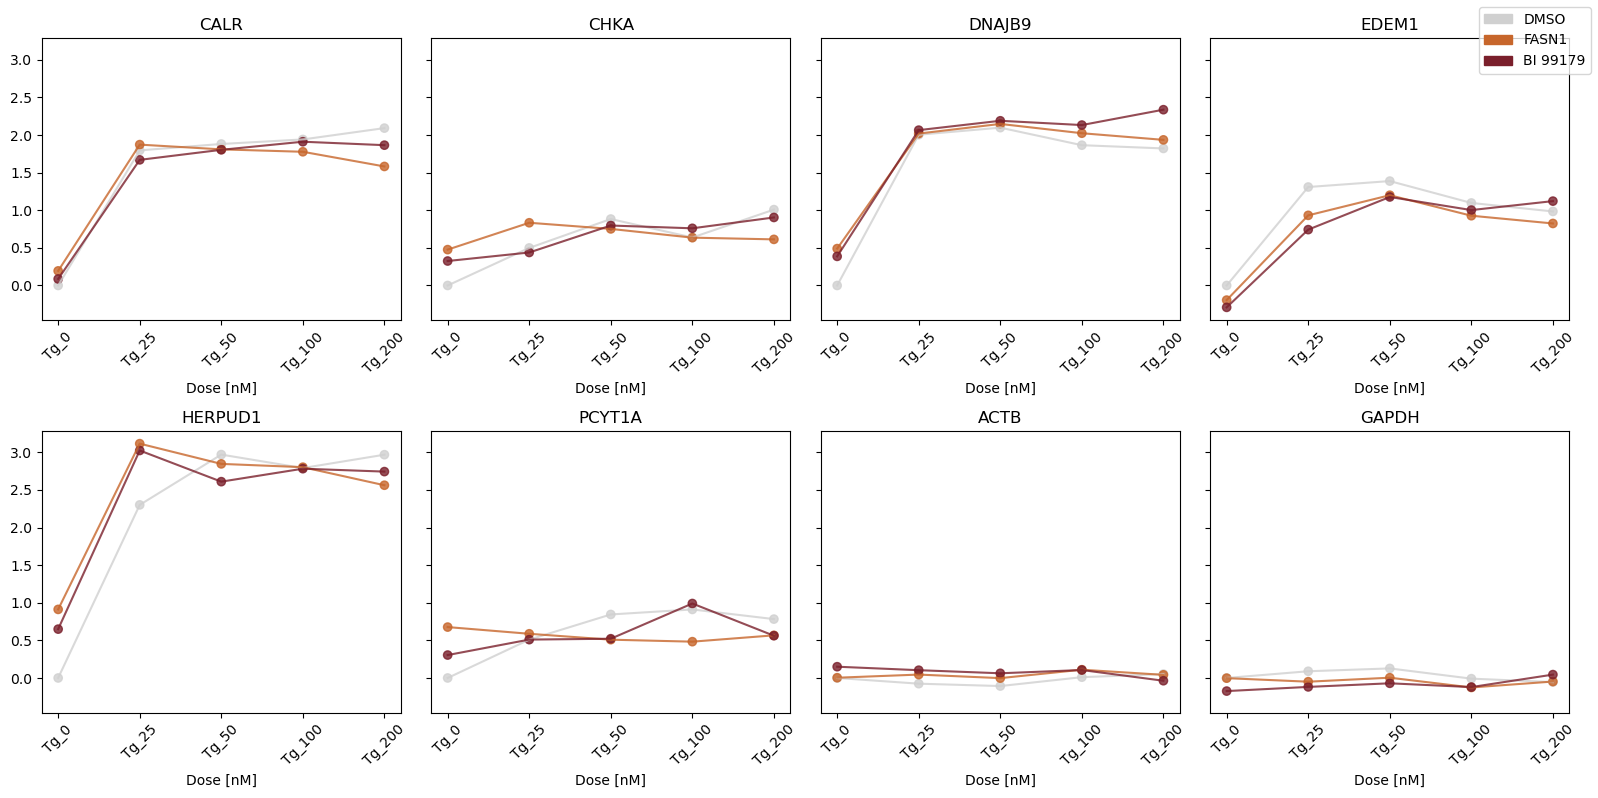

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

df = qpcr_data_final.copy()

dose_levels = ["Tg_0", "Tg_25", "Tg_50", "Tg_100", "Tg_200"]
dose_order = {d: i for i, d in enumerate(dose_levels)}

def sample_dose(s):
    for d in dose_levels:
        if d in s:
            return d
    return None

def sample_color(s):
    if "-D-" in s:
        return "#d0d0d0"  # light grey
    if "-F1-" in s:
        return "#c7662b"  # burnt orange
    if "-Fnd-" in s:
        return "#7a1f2b"  # burgundy
    return "#4a4a4a"      # fallback

df["dose"] = df["Sample"].apply(sample_dose)
df["color"] = df["Sample"].apply(sample_color)
df = df[df["dose"].notna()]


all_targets = df["Target"].unique()
non_hk = [t for t in all_targets if t not in hk_genes]
hk = [t for t in all_targets if t in hk_genes]
targets = (non_hk + hk)[:8]  # first 8, with HK last

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for ax, target in zip(axes, targets):
    sub = df[df["Target"] == target].copy()
    sub["dose_idx"] = sub["dose"].map(dose_order)

    # scatter points by sample
    ax.scatter(
        sub["dose_idx"],
        -sub["delta_delta"],  # negative Delta Delta
        c=sub["color"],
        alpha=0.8,
    )

    # connect points of same color in dose order
    for color in ["#d0d0d0", "#c7662b", "#7a1f2b"]:
        csub = sub[sub["color"] == color].sort_values("dose_idx")
        if not csub.empty:
            ax.plot(csub["dose_idx"], -csub["delta_delta"], color=color, alpha=0.8)

    ax.set_title(target)
    ax.set_xlabel("Dose [nM]")
    ax.set_xticks(range(len(dose_levels)))
    ax.set_xticklabels(dose_levels, rotation=45)

for ax in axes[len(targets):]:
    ax.axis("off")

fig.tight_layout()
legend_handles = [
    mpatches.Patch(color="#d0d0d0", label="DMSO"),
    mpatches.Patch(color="#c7662b", label="FASN1"),
    mpatches.Patch(color="#7a1f2b", label="BI 99179"),
]

fig.legend(handles=legend_handles, loc="upper right")
plt.show()
